In [27]:
import pandas as pd
import numpy as np

## Melihat distribusi order status

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


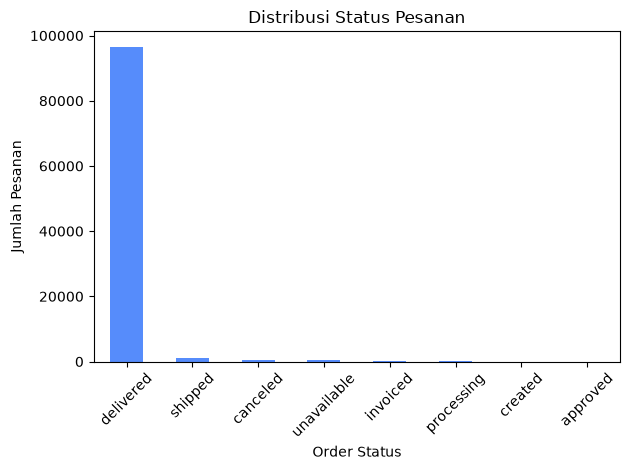

In [28]:
import matplotlib.pyplot as plt

status_count = orders["order_status"].value_counts()

print(status_count)

status_count.plot(kind="bar")
plt.title("Distribusi Status Pesanan")
plt.xlabel("Order Status")
plt.ylabel("Jumlah Pesanan")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Cek Missing Value dan Duplicates

In [29]:
missing = orders.isnull().sum()
duplicated = orders.duplicated().sum()

missing_table = pd.DataFrame({
    "Jumlah Missing Value": missing,
    "Persentase (%)": (missing / len(orders) * 100).round(2)
})

duplicate_table = pd.DataFrame({
    "Jumlah Duplicated Value": [duplicated]
})

print("Missing Value:")
print(missing_table)

print("\nDuplicated Value:")
print(duplicate_table)

Missing Value:
                               Jumlah Missing Value  Persentase (%)
order_id                                          0            0.00
customer_id                                       0            0.00
order_status                                      0            0.00
order_purchase_timestamp                          0            0.00
order_approved_at                               160            0.16
order_delivered_carrier_date                   1783            1.79
order_delivered_customer_date                  2965            2.98
order_estimated_delivery_date                     0            0.00
delivery_status                                2971            2.99

Duplicated Value:
   Jumlah Duplicated Value
0                        0


## Perbandingan Estimasi dan Durasi Pengiriman Aktual


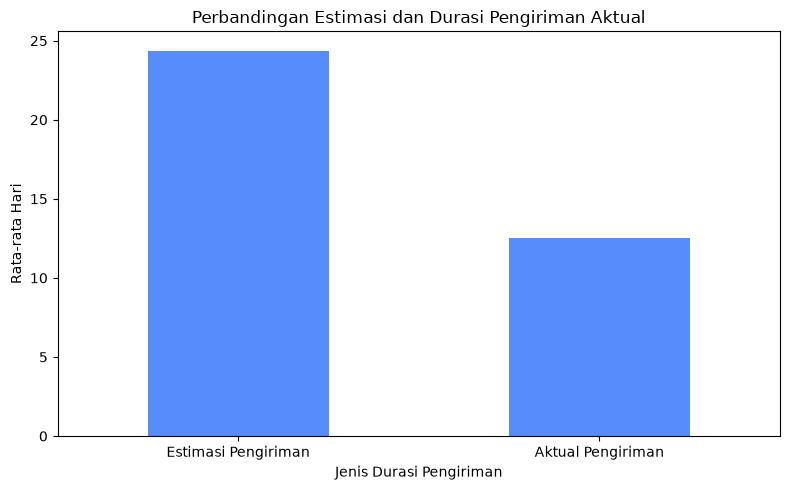

estimasi_hari    24.372738
aktual_hari      12.496849
dtype: float64


In [30]:

# Konversi kolom tanggal
orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"]
)
orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"]
)
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

# Ambil pesanan yang sudah delivered dan tanggalnya lengkap
data = orders[
    (orders["order_status"] == "delivered") &
    orders["order_delivered_customer_date"].notna() &
    orders["order_estimated_delivery_date"].notna()
].copy()

# Hitung durasi estimasi dan aktual dalam hari
data["estimasi_hari"] = (
    data["order_estimated_delivery_date"].dt.normalize() -
    data["order_purchase_timestamp"].dt.normalize()
).dt.days

data["aktual_hari"] = (
    data["order_delivered_customer_date"].dt.normalize() -
    data["order_purchase_timestamp"].dt.normalize()
).dt.days

# Bandingkan rata-rata
perbandingan = data[["estimasi_hari", "aktual_hari"]].mean()

perbandingan.plot(kind="bar", figsize=(8, 5))

plt.title("Perbandingan Estimasi dan Durasi Pengiriman Aktual")
plt.xlabel("Jenis Durasi Pengiriman")
plt.ylabel("Rata-rata Hari")
plt.xticks(
    ticks=[0, 1],
    labels=["Estimasi Pengiriman", "Aktual Pengiriman"],
    rotation=0
)
plt.tight_layout()
plt.show()

print(perbandingan)

## Persentase Status Pengiriman

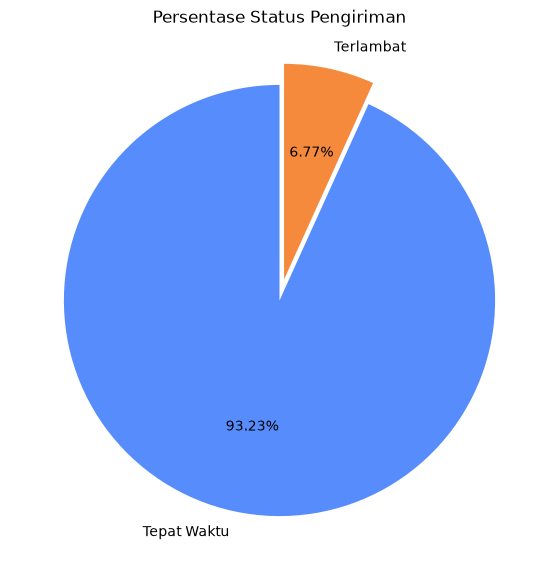

        Status  Jumlah  Persentase (%)
0  Tepat Waktu   89936           93.23
1    Terlambat    6534            6.77


In [31]:
# Hitung status keterlambatan
data["delivery_status"] = (
    data["order_delivered_customer_date"].dt.normalize() >
    data["order_estimated_delivery_date"].dt.normalize()
).astype(int)

# Hitung jumlah dan persentase
status_count = data["delivery_status"].value_counts().sort_index()

status_table = pd.DataFrame({
    "Status": ["Tepat Waktu", "Terlambat"],
    "Jumlah": [
        status_count.get(0, 0),
        status_count.get(1, 0)
    ]
})

status_table["Persentase (%)"] = (
    status_table["Jumlah"] / status_table["Jumlah"].sum() * 100
).round(2)

plt.figure(figsize=(7, 7))

labels = ["Tepat Waktu", "Terlambat"]
values = [
    (data["delivery_status"] == 0).sum(),
    (data["delivery_status"] == 1).sum()
]

plt.pie(
    values,
    labels=labels,
    autopct="%1.2f%%",
    startangle=90,
    explode=(0, 0.1)
)

plt.title("Persentase Status Pengiriman")
plt.show()
print(status_table)

## Distribusi Durasi Keterlambatan Pengiriman

In [32]:
# Hitung durasi keterlambatan dalam hari
data["durasi_keterlambatan"] = (
    data["order_delivered_customer_date"].dt.normalize() -
    data["order_estimated_delivery_date"].dt.normalize()
).dt.days

# Ambil pesanan yang terlambat saja
terlambat = data[data["durasi_keterlambatan"] > 0]

# Statistik durasi keterlambatan
print(terlambat["durasi_keterlambatan"].describe())

count    6534.000000
mean       10.620141
std        14.644955
min         1.000000
25%         3.000000
50%         7.000000
75%        13.000000
max       188.000000
Name: durasi_keterlambatan, dtype: float64


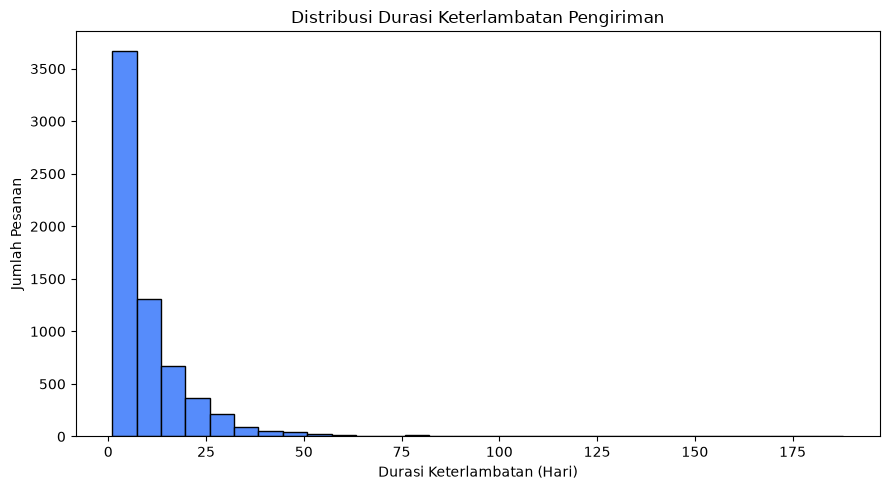

In [33]:
plt.figure(figsize=(9, 5))

plt.hist(
    terlambat["durasi_keterlambatan"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribusi Durasi Keterlambatan Pengiriman")
plt.xlabel("Durasi Keterlambatan (Hari)")
plt.ylabel("Jumlah Pesanan")
plt.tight_layout()
plt.show()

In [34]:
jumlah_terlambat = (data["delivery_status"] == 1).sum()
total_pesanan = len(data)

persentase = jumlah_terlambat / total_pesanan * 100

print("Jumlah terlambat:", jumlah_terlambat)
print("Total pesanan:", total_pesanan)
print("Persentase terlambat:", round(persentase, 2), "%")

Jumlah terlambat: 6534
Total pesanan: 96470
Persentase terlambat: 6.77 %
